# La transition vers la voiture électrique en France : statistiques descriptives à l'échelle des communes

**Question de recherche.** Comment la part des voitures 100 % électriques varie-t-elle entre les communes de France métropolitaine, et comment ces écarts se répartissent-ils selon le niveau de vie, la position dans les aires d'attraction des villes et l'offre de recharge publique ?

Le notebook appelle les fonctions des modules du dossier `src/` :

| Module | Rôle |
|---|---|
| `config.py` | chemins relatifs, noms des fichiers, modalités et constantes |
| `preparation.py` | lecture et nettoyage de chaque source |
| `fusion.py` | jointures et tableau de couverture |
| `indicateurs.py` | parts électriques, résumés par groupe, quartiles de revenu, tableau régional |
| `graphiques.py` | graphiques |

Les fichiers bruts doivent être placés dans `data/raw/` (voir le README).

## 1. Introduction

*À rédiger : contexte, problématique, hypothèses (territoire, niveau de vie, recharge et logement).*

**Champ et définitions**
- Voitures particulières (catégorie `VP` du SDES), tous statuts d'utilisateurs ; vérification sur les seuls ménages (statut « Particulier » dans le parc, « PP » dans les immatriculations).
- **Parc** : voitures en circulation au 1er janvier 2026. **Neuf** : immatriculations de voitures neuves pendant l'année 2025. **Occasion** (extension) : opérations d'immatriculation de voitures d'occasion en 2025.
- **Électrique** : modalité « Electrique » dans le parc ; « Electrique et hydrogène » dans les immatriculations (le SDES ne sépare pas l'hydrogène dans ces fichiers, son poids est négligeable). Les hybrides rechargeables restent au dénominateur.
- France métropolitaine, Corse comprise, géographie communale au 1er janvier 2026.

In [1]:
import pandas as pd

from src import config
from src import preparation as prep
from src import fusion
from src import indicateurs as ind
from src import graphiques as graph

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
graph.appliquer_style()

# Vérification : quels fichiers bruts sont présents dans data/raw/ ?
for cle, nom in config.FICHIERS.items():
    present = (config.DOSSIER_BRUT / nom).exists()
    print(f"{cle:10s} {'OK      ' if present else 'MANQUANT'} {nom}")

parc       OK       Donnees-sur-le-parc-de-vehicules-au-niveau-communal_2026-06.csv
neuf       OK       Immatriculations-de-vehicules-achetes-neufs-au-niveau-communal_2026-02.csv
occasion   OK       Immatriculations-de-vehicules-achetes-doccasion-au-niveau-communal_2026-02.csv
aav        OK       AAV2020_au_01-01-2026.xlsx
filosofi   OK       DS_FILOSOFI_CC_2023_data.csv
irve       OK       consolidation-etalab-schema-irve-statique-v-2_3_1-20261019.csv
bpe        OK       DS_BPE_2025_data.csv
population OK       DS_POPULATIONS_REFERENCE_2023_data.csv
contours   MANQUANT communes-50m.geojson


## 2. Données et traitements

### 2.1 Référentiel des communes : aires d'attraction des villes (Insee)

Le classeur AAV (géographie au 1er janvier 2026) sert de référentiel : il liste toutes les communes avec leur département et leur région. On joint l'onglet de composition communale (position de la commune) et la liste des aires (taille de l'aire).

In [2]:
aav = prep.preparer_aav()
print(f"Communes de France métropolitaine : {len(aav):,}")
print(f"Codes commune uniques : {aav['code_commune'].is_unique}")
aav.head()

Communes de France métropolitaine : 34,746
Codes commune uniques : True


,code_commune,nom_commune,AAV2020,LIBAAV2020,CATEAAV2020,DEP,REG,TAAV2017,position_aav,taille_aav,region
0,01001,L'Abergement-Clémenciat,524,Châtillon-sur-Chalaronne,20,01,84,1,Couronne,Moins de 50 000 hab.,Auvergne-Rhône-Alpes
1,01002,L'Abergement-de-Varey,000,Commune hors attraction des villes,30,01,84,0,Hors attraction,Hors attraction,Auvergne-Rhône-Alpes
2,01004,Ambérieu-en-Bugey,243,Ambérieu-en-Bugey,11,01,84,1,Pôle,Moins de 50 000 hab.,Auvergne-Rhône-Alpes
3,01005,Ambérieux-en-Dombes,002,Lyon,20,01,84,4,Couronne,700 000 hab. ou plus (hors Paris),Auvergne-Rhône-Alpes
4,01006,Ambléon,286,Belley,20,01,84,1,Couronne,Moins de 50 000 hab.,Auvergne-Rhône-Alpes


In [3]:
# Répartition des communes par position et par taille d'aire
pd.crosstab(aav["taille_aav"], aav["position_aav"], margins=True, margins_name="Total")

position_aav,Pôle,Couronne,Hors attraction,Total
taille_aav,,,,
Hors attraction,0,0,8875,8875
Moins de 50 000 hab.,761,7053,0,7814
50 000 à 200 000 hab.,226,7562,0,7788
200 000 à 700 000 hab.,221,5390,0,5611
700 000 hab. ou plus (hors Paris),169,2563,0,2732
Aire de Paris,336,1590,0,1926
Total,1713,24158,8875,34746


### 2.2 Parc et immatriculations (SDES)

Les fichiers DiDo du SDES ont une ligne par commune × motorisation × statut de l'utilisateur (× vignette Crit'Air). Il n'existe pas de ligne « Ensemble » : le total d'une commune est la somme de toutes les motorisations, y compris « Inconnu ».

Paris, Lyon et Marseille sont détaillés par arrondissement dans le parc : on additionne les arrondissements pour revenir au code de la commune.

In [4]:
# Parc : on lit toutes les années pour la série nationale
parc_brut = prep.lire_fichier_sdes("parc", [f"PARC_{a}" for a in range(2011, config.ANNEE_PARC + 1)])
print("Motorisations du parc :", sorted(parc_brut["CARBURANT"].unique()))
print("Statuts :", sorted(parc_brut["STATUT_UTILISATEUR"].unique()))

parc = prep.preparer_vehicules(parc_brut, f"PARC_{config.ANNEE_PARC}",
                               config.ELEC_PARC, config.MENAGE_PARC, "parc")
serie_parc = prep.serie_metropole(parc_brut, "PARC_", config.ELEC_PARC)
del parc_brut   # libère la mémoire
parc.head()

Motorisations du parc : ['Diesel', 'Diesel HNR', 'Diesel HR', 'Electrique', 'Essence', 'Essence HNR', 'Essence HR', 'Gaz', 'Gaz HNR', 'Gaz HR', 'Hydrogène et autre ZE', 'Inconnu']
Statuts : ['Particulier', 'Professionel']


,code_commune,vp_parc,vp_parc_elec,vp_parc_men,vp_parc_elec_men
0,00000,852,15,575,12
1,01000,348,6,341,6
2,01001,593,19,588,18
3,01002,173,3,173,3
4,01004,9454,387,8747,322


In [5]:
# Immatriculations de voitures neuves
neuf_brut = prep.lire_fichier_sdes("neuf", [f"IMMAT_{a}" for a in range(2010, config.ANNEE_IMMAT + 1)])
print("Motorisations :", sorted(neuf_brut["CARBURANT"].unique()))
print("Statuts :", neuf_brut["STATUT_UTILISATEUR"].value_counts(dropna=False).to_dict())

neuf = prep.preparer_vehicules(neuf_brut, f"IMMAT_{config.ANNEE_IMMAT}",
                               config.ELEC_IMMAT, config.MENAGE_IMMAT, "neuf")
serie_neuf = prep.serie_metropole(neuf_brut, "IMMAT_", config.ELEC_IMMAT)
del neuf_brut

# Immatriculations de voitures d'occasion (extension)
occasion_brut = prep.lire_fichier_sdes("occasion", [f"IMMAT_{config.ANNEE_IMMAT}"])
occasion = prep.preparer_vehicules(occasion_brut, f"IMMAT_{config.ANNEE_IMMAT}",
                                   config.ELEC_IMMAT, config.MENAGE_IMMAT, "occasion")
del occasion_brut
neuf.head()

Motorisations : ['Diesel - hybride NR', 'Diesel - thermique', 'Electrique et hydrogène', 'Essence - hybride NR', 'Essence - thermique', 'Gaz et ND', 'Hybride rechargeable']
Statuts : {'PP': 199547, 'PM': 111943, nan: 15547}


,code_commune,vp_neuf,vp_neuf_elec,vp_neuf_men,vp_neuf_elec_men
0,00000,0,0,0,0
1,01000,0,0,0,0
2,01001,17,6,14,4
3,01002,2,0,2,0
4,01004,246,64,158,49


Les codes présents dans les fichiers SDES mais absents du référentiel doivent être des DOM ou des codes fictifs (numéro de département suivi de `000` quand la commune est inconnue) :

In [6]:
hors = fusion.codes_hors_referentiel(parc, aav, "vp_parc")
hors["type"] = "autre"
hors.loc[hors["code_commune"].str.startswith("97"), "type"] = "DOM"
hors.loc[hors["code_commune"].str.endswith("000"), "type"] = "code fictif (commune inconnue)"
hors.groupby("type")["vp_parc"].agg(["count", "sum"])

,count,sum
type,,
DOM,134,933907
code fictif (commune inconnue),96,12138


### 2.3 Revenus : Filosofi 2023 (Insee)

Niveau de vie médian annuel (`MED_SL`) et taux de pauvreté (`PR_MD60`) des communes. Les valeurs sous secret statistique restent manquantes.

In [7]:
filosofi = prep.preparer_filosofi()
print(f"Communes avec un niveau de vie médian : {filosofi['niveau_vie_median'].notna().sum():,}")
filosofi.head()

Communes avec un niveau de vie médian : 30,794


,code_commune,niveau_vie_median,taux_pauvrete
0,01001,"28,270.00",NaN
1,01002,"28,140.00",NaN
2,01004,"24,210.00",18.00
3,01005,"28,120.00",5.00
4,01006,NaN,NaN


### 2.4 Points de recharge ouverts au public (IRVE)

Base nationale consolidée (transport.data.gouv.fr), archive du 19/10/2026. Le fichier a une ligne par point de charge. On supprime les doublons d'identifiant, puis on rattache chaque point à une commune par son code Insee et, si les contours communaux sont disponibles, par ses coordonnées.

**Attention aux dates** : le parc est mesuré au 1er janvier 2026 et l'IRVE à une date plus récente. Le croisement est une analyse complémentaire à dates décalées.

In [8]:
irve, points_irve = prep.preparer_irve(aav["code_commune"])
print(points_irve["rattachement"].value_counts())

# L'information "aucun point recensé" n'est fiable que si (presque) tous les points sont rattachés
part_non_apparies = (points_irve["rattachement"] == "non apparié").mean()
irve_exhaustif = part_non_apparies < 0.05
print(f"Part des points non rattachés : {100 * part_non_apparies:.1f} % -> IRVE exhaustif : {irve_exhaustif}")

Lignes dans le fichier IRVE : 157,460
Doublons d'identifiant supprimés : 7,919


Contours communaux absents (communes-50m.geojson).
Pas de rattachement des bornes par coordonnées.
rattachement
code Insee     78942
non apparié    70599
Name: count, dtype: int64
Part des points non rattachés : 47.2 % -> IRVE exhaustif : False


### 2.5 Population et équipements de transport (Insee)

- **Population municipale** : dénominateur des indicateurs « pour 1 000 habitants ».
- **Populations de référence 2023** (population au 1er janvier 2023, limites communales 2025) : quelques communes créées ou fusionnées au 1er janvier 2026 peuvent manquer, voir le tableau de couverture.
- **BPE 2025** : nombre de gares de voyageurs (types E107, E108, E109) et d'équipements de transport (domaine E : gares, taxis-VTC, aéroports) par commune. Une commune absente de la BPE n'a aucun équipement recensé (0). Les taxis-VTC représentent l'essentiel des équipements de transport.

In [9]:
population = prep.preparer_population()
bpe = prep.preparer_bpe()
print(f"Communes avec une population : {len(population):,}")
print(f"Communes avec au moins un équipement de transport : {len(bpe):,}")

Équipements de transport par type (France entière) :
FACILITY_TYPE
E101    96253
E102       89
E107      114
E108     1044
E109     1780
Name: OBS_VALUE, dtype: int64
Communes avec une population : 34,858
Communes avec au moins un équipement de transport : 10,395


### 2.6 Assemblage et tableau de couverture

On part du référentiel et on ajoute chaque table par une jointure à gauche. Le nombre de communes ne doit pas changer.

In [10]:
base, couverture = fusion.construire_base(aav, {
    "Parc au 01/01/2026": parc,
    "Neuf 2025": neuf,
    "Occasion 2025": occasion,
    "Filosofi 2023": filosofi,
    "IRVE": irve,
    "Population": population,
    "BPE 2025": bpe,
})
base = ind.calculer_indicateurs(base, irve_exhaustif)
couverture

,communes du référentiel,communes appariées,communes sans donnée,codes de la source hors référentiel
source,,,,
Parc au 01/01/2026,34746,34742,4,230
Neuf 2025,34746,34719,27,229
Occasion 2025,34746,34744,2,232
Filosofi 2023,34746,34744,2,24
IRVE,34746,6986,27760,0
Population,34746,34746,0,112
BPE 2025,34746,10276,24470,119


In [11]:
# Contrôles de cohérence : toutes les colonnes doivent valoir 0, sauf les parts indéfinies
ind.controler_base(base)

,effectifs négatifs,électriques > total,"parts hors [0, 100]",parts indéfinies (total = 0 ou manquant)
table,,,,
parc,0,0,0,4
neuf,0,0,0,3250
occasion,0,0,0,95


In [12]:
# Comparaison avec le total national métropolitain (l'écart = codes fictifs des départements)
total_base = base["vp_parc"].sum()
total_national = serie_parc.loc[serie_parc["annee"] == config.ANNEE_PARC, "total"].iloc[0]
print(f"Parc dans la base communale : {total_base:,.0f}")
print(f"Parc France métropolitaine  : {total_national:,.0f}")
print(f"Écart : {total_national - total_base:,.0f} voitures ({100 * (1 - total_base / total_national):.3f} %)")

Parc dans la base communale : 39,001,252
Parc France métropolitaine  : 39,012,538
Écart : 11,286 voitures (0.029 %)


In [13]:
# Cas connus : zéro initial (01001), Corse (2A004), Paris (arrondissements regroupés), commune hors attraction
exemple_hors_attraction = base.loc[base["position_aav"] == "Hors attraction", "code_commune"].iloc[0]
fusion.verifier_cas_connus(base, ["01001", "2A004", "75056", exemple_hors_attraction],
                           ["position_aav", "taille_aav", "vp_parc", "vp_parc_elec", "part_parc", "part_neuf", "nb_points"])

,code_commune,nom_commune,position_aav,taille_aav,vp_parc,vp_parc_elec,part_parc,part_neuf,nb_points
0,01001,L'Abergement-Clémenciat,Couronne,Moins de 50 000 hab.,593.00,19.00,3.20,35.29,NaN
1,01002,L'Abergement-de-Varey,Hors attraction,Hors attraction,173.00,3.00,1.73,0.00,NaN
10514,2A004,Ajaccio,Pôle,50 000 à 200 000 hab.,"38,513.00","1,202.00",3.12,6.72,52.00
29194,75056,Paris,Pôle,Aire de Paris,"603,164.00","38,163.00",6.33,12.78,"4,420.00"


In [14]:
# Sauvegarde de la table préparée (dans data/processed/, non versionné)
config.DOSSIER_PREP.mkdir(exist_ok=True)
base.to_csv(config.DOSSIER_PREP / "base_communale.csv", index=False)

## 3. Panorama territorial

### 3.1 Carte de la part électrique du parc
Classes fixes, communes sans donnée en gris (nécessite les contours IGN dans `data/raw/`).

In [15]:
graph.tracer_carte(base, "part_parc", "Part des voitures électriques dans le parc au 1er janvier 2026",
                   "carte_part_parc");

Contours communaux absents (communes-50m.geojson).
Carte non tracée.


### 3.2 Carte interactive par département

Survoler un département affiche ses indicateurs ; la molette permet de zoomer. Chaque indicateur est calculé sur le total du département (somme des voitures électriques / somme des voitures). La carte est aussi enregistrée dans `figures/carte_departements.html`, à ouvrir dans un navigateur (GitHub n'affiche pas les cartes interactives).

In [16]:
departements = ind.tableau_synthese(base, "DEP").drop(index="France métropolitaine")
contours_dep = prep.lire_departements()

graph.tracer_carte_interactive(
    departements, contours_dep,
    colonne="part VE parc (%)",
    titre="Part des voitures électriques dans le parc au 1er janvier 2026, par département",
    nom_fichier="carte_departements",
    infos=["taux VE immat. neuves (%)", "points pour 1 000 hab.", "points pour 100 VE", "communes avec gare (%)"],
)

Téléchargement des contours des départements : https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements-version-simplifiee.geojson


**Commentaire :** *À rédiger.* Pour cartographier un autre indicateur, il suffit de changer `colonne` (par exemple `"taux VE immat. neuves (%)"`).

### 3.3 Parts par région

In [17]:
resume_region = ind.resume_par_groupe(base, "region", "parc")
resume_region

,nb_communes,q1,mediane,q3,vp_elec,vp_total,part_agregee
region,,,,,,,
Auvergne-Rhône-Alpes,4025,1.79,2.86,4.06,"184,139.00","5,084,117.00",3.62
Bourgogne-Franche-Comté,3685,1.12,2.07,3.06,"46,523.00","1,815,911.00",2.56
Bretagne,1202,1.88,2.54,3.29,"67,378.00","2,216,100.00",3.04
Centre-Val de Loire,1754,1.52,2.33,3.31,"46,720.00","1,641,713.00",2.85
Corse,360,1.28,3.01,4.61,"11,190.00","224,214.00",4.99
Grand Est,5111,1.51,2.63,3.99,"114,399.00","3,457,406.00",3.31
Hauts-de-France,3782,1.67,2.61,3.73,"116,566.00","3,543,980.00",3.29
Normandie,2644,1.92,2.86,4.03,"69,073.00","2,101,273.00",3.29
Nouvelle-Aquitaine,4293,1.52,2.38,3.26,"121,520.00","4,037,071.00",3.01


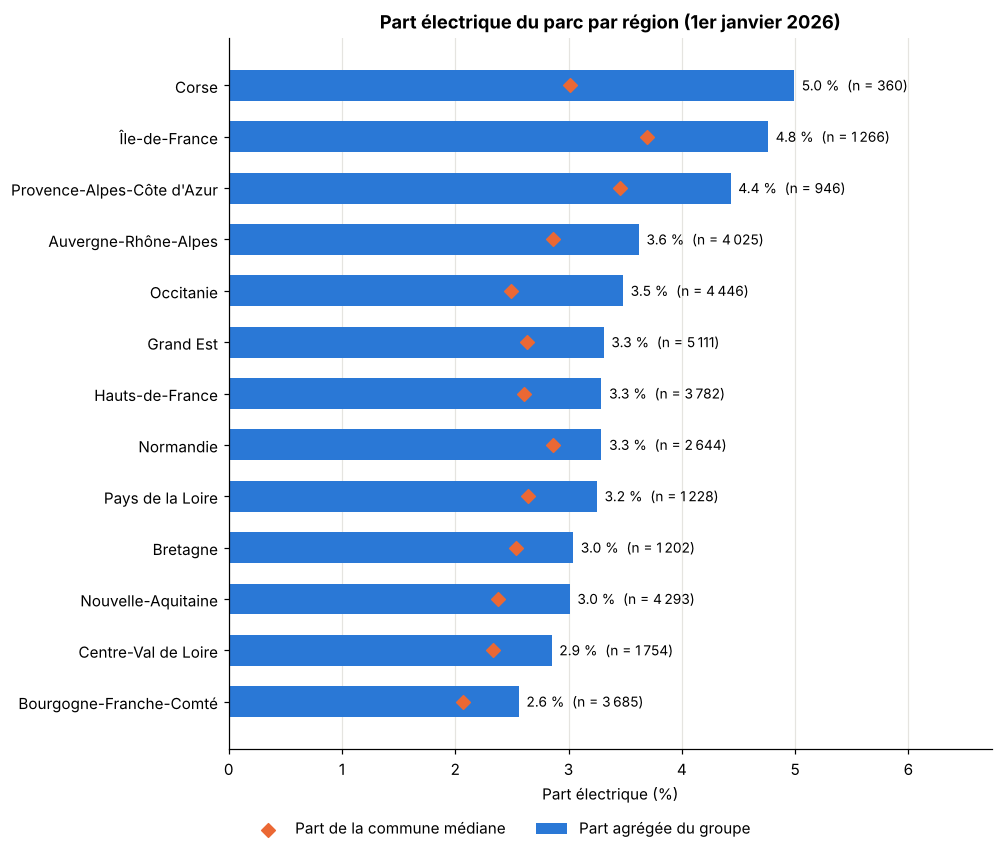

In [18]:
graph.tracer_barres(resume_region, "Part électrique du parc par région (1er janvier 2026)",
                    "regions_parc");

**Commentaire :** *À rédiger. Indiquer ce qui est comparé, un ordre de grandeur en points, et si le résultat vaut pour la commune médiane (losange) ou pour l'ensemble des voitures de la région (barre).*

## 4. Parc et marché du neuf

### 4.1 Tendance en France métropolitaine
Convention : les immatriculations de l'année *t* sont associées au parc au 1er janvier de *t + 1*.

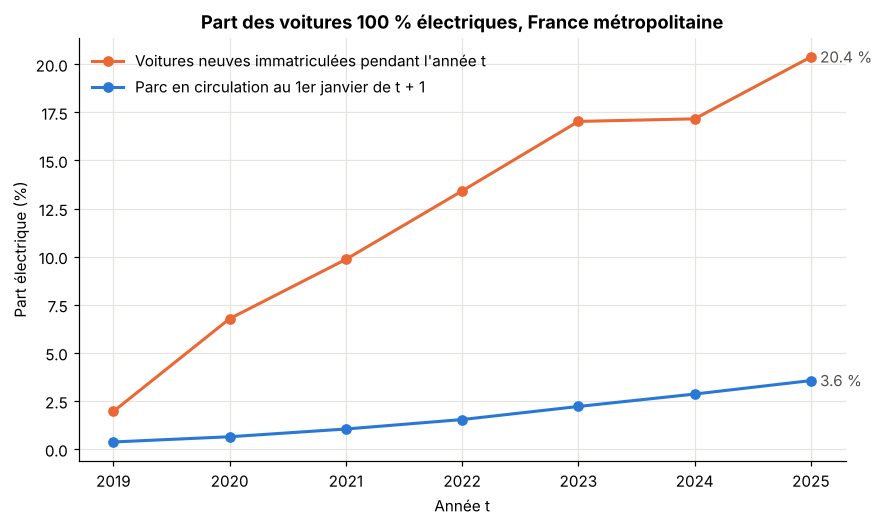

In [19]:
graph.tracer_tendance(serie_parc, serie_neuf, debut=2019, fin=2025);

**Commentaire :** *À rédiger.*

### 4.2 Parc et neuf par type de territoire (écart en points de pourcentage)

In [20]:
comparaison = pd.DataFrame({
    "part parc 01/01/2026 (%)": ind.resume_par_groupe(base, "position_aav", "parc")["part_agregee"],
    "part neuf 2025 (%)": ind.resume_par_groupe(base, "position_aav", "neuf")["part_agregee"],
})
comparaison["écart (points)"] = comparaison["part neuf 2025 (%)"] - comparaison["part parc 01/01/2026 (%)"]
comparaison

,part parc 01/01/2026 (%),part neuf 2025 (%),écart (points)
position_aav,,,
Pôle,3.76,19.21,15.45
Couronne,3.57,22.18,18.61
Hors attraction,2.38,20.10,17.72


In [21]:
# Même comparaison par région
comparaison_regions = pd.DataFrame({
    "part parc (%)": resume_region["part_agregee"],
    "part neuf 2025 (%)": ind.resume_par_groupe(base, "region", "neuf")["part_agregee"],
})
comparaison_regions["écart (points)"] = comparaison_regions["part neuf 2025 (%)"] - comparaison_regions["part parc (%)"]
comparaison_regions.sort_values("part neuf 2025 (%)")

,part parc (%),part neuf 2025 (%),écart (points)
region,,,
Hauts-de-France,3.29,17.07,13.78
Normandie,3.29,18.40,15.11
Bourgogne-Franche-Comté,2.56,18.97,16.41
Nouvelle-Aquitaine,3.01,19.05,16.04
Corse,4.99,19.22,14.23
Centre-Val de Loire,2.85,19.80,16.95
Bretagne,3.04,20.10,17.06
Île-de-France,4.76,20.48,15.72
Grand Est,3.31,20.93,17.62


**Commentaire :** *À rédiger.*

## 5. Niveau de vie

Quartiles de niveau de vie médian communal (le nombre de groupes se règle dans `config.NB_GROUPES_REVENU`), calculés sur les communes avec un niveau de vie connu et au moins une voiture.

In [22]:
base, bornes_revenu = ind.ajouter_groupes_revenu(base)
print("Bornes des quartiles (euros par an) :", bornes_revenu)

Bornes des quartiles (euros par an) : [12420. 24090. 25780. 27830. 62730.]


,nb_communes,q1,mediane,q3,vp_elec,vp_total,part_agregee
groupe_revenu,,,,,,,
Q1 (plus modestes),7701,1.22,1.93,2.68,"335,314.00","11,713,531.00",2.86
Q2,7698,1.57,2.34,3.13,"222,242.00","7,588,756.00",2.93
Q3,7688,2.04,2.86,3.74,"279,918.00","8,030,868.00",3.49
Q4 (plus aisées),7683,2.97,3.97,5.08,"547,416.00","11,465,819.00",4.77


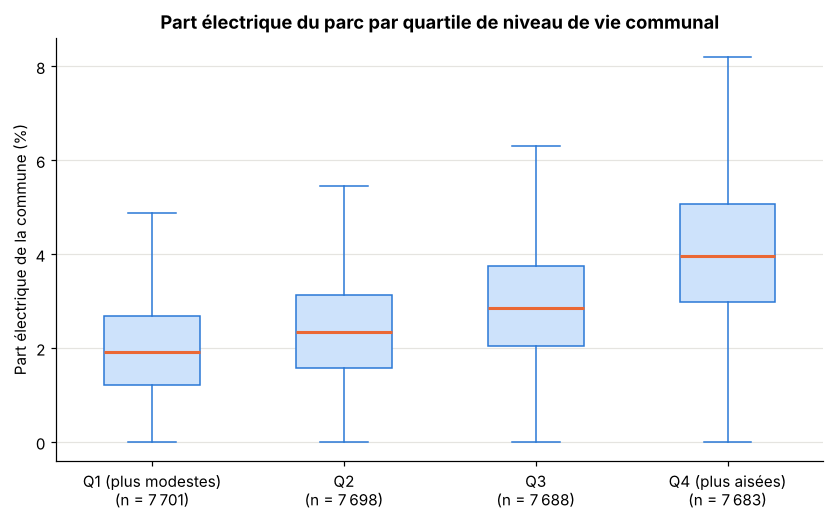

In [23]:
if bornes_revenu is not None:
    graph.tracer_boites(base, "groupe_revenu", "part_parc",
                        "Part électrique du parc par quartile de niveau de vie communal",
                        "boites_revenu_parc")
    display(ind.resume_par_groupe(base, "groupe_revenu", "parc"))

In [24]:
# Vérification sur les seuls ménages : l'ordre des groupes est-il le même ?
if bornes_revenu is not None:
    display(pd.concat({
        "tous utilisateurs": ind.resume_par_groupe(base, "groupe_revenu", "parc")[["nb_communes", "mediane", "part_agregee"]],
        "ménages": ind.resume_par_groupe(base, "groupe_revenu", "parc", menages=True)[["nb_communes", "mediane", "part_agregee"]],
    }, axis=1))

tous utilisateurs                          ménages          \
                         nb_communes mediane part_agregee nb_communes mediane   
groupe_revenu                                                                   
Q1 (plus modestes)              7701    1.93         2.86        7701    1.73   
Q2                              7698    2.34         2.93        7698    2.19   
Q3                              7688    2.86         3.49        7688    2.68   
Q4 (plus aisées)                7683    3.97         4.77        7683    3.69   

                                 
                   part_agregee  
groupe_revenu                    
Q1 (plus modestes)         1.98  
Q2                         2.40  
Q3                         2.89  
Q4 (plus aisées)           3.82

**Commentaire :** *À rédiger.*

## 6. Pôles et couronnes

In [25]:
resume_position = ind.resume_par_groupe(base, "position_aav", "parc")
resume_position

,nb_communes,q1,mediane,q3,vp_elec,vp_total,part_agregee
position_aav,,,,,,,
Pôle,1713,2.20,2.87,3.75,"629,594.00","16,737,786.00",3.76
Couronne,24156,1.83,2.81,3.99,"687,730.00","19,248,811.00",3.57
Hors attraction,8873,1.00,1.92,2.94,"71,700.00","3,014,655.00",2.38


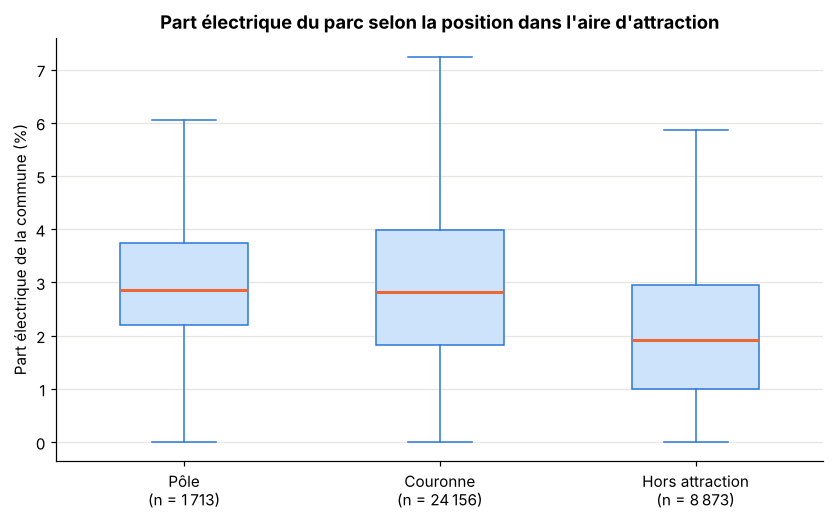

In [26]:
graph.tracer_boites(base, "position_aav", "part_parc", "Part électrique du parc selon la position dans l'aire d'attraction",
                    "boites_position_parc");

Nombre de communes par case :


position_aav,Pôle,Couronne
taille_aav,,
Moins de 50 000 hab.,761,7051
50 000 à 200 000 hab.,226,7562
200 000 à 700 000 hab.,221,5390
700 000 hab. ou plus (hors Paris),169,2563
Aire de Paris,336,1590


Communes hors attraction :


,nb_communes,q1,mediane,q3,vp_elec,vp_total,part_agregee
position_aav,,,,,,,
Hors attraction,8873,1.00,1.92,2.94,"71,700.00","3,014,655.00",2.38


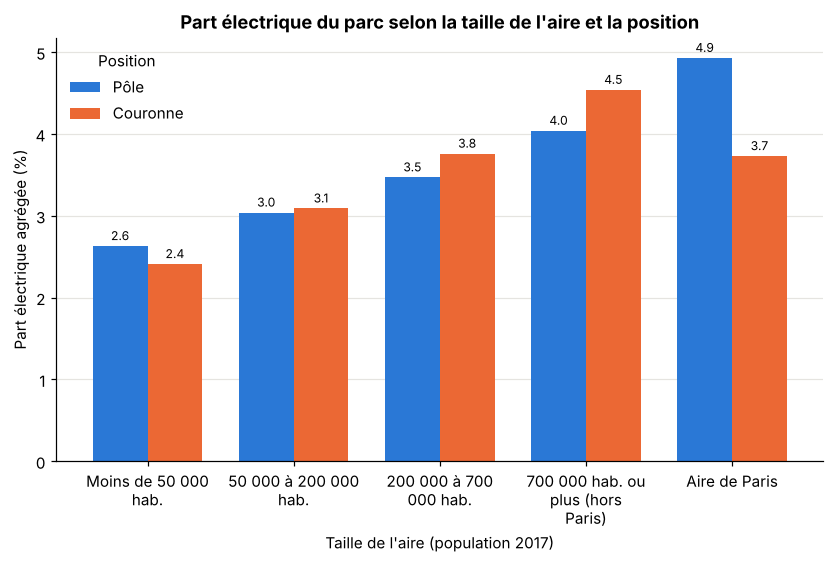

In [27]:
# Croisement position x taille de l'aire (le groupe hors attraction est présenté à part)
dans_une_aire = base[base["position_aav"] != "Hors attraction"]
parts_taille, n_taille = ind.tableau_croise(dans_une_aire, "taille_aav", "position_aav", "parc")
parts_taille = parts_taille.drop(columns="Hors attraction", errors="ignore")

graph.tracer_barres_groupees(parts_taille, "Part électrique du parc selon la taille de l'aire et la position",
                             "barres_taille_position", label_x="Taille de l'aire (population 2017)",
                             label_legende="Position")
print("Nombre de communes par case :")
display(n_taille)
print("Communes hors attraction :")
display(resume_position.loc[["Hors attraction"]])

**Commentaire :** *À rédiger.*

## 7. Croisements

### 7.1 Niveau de vie × position dans l'aire

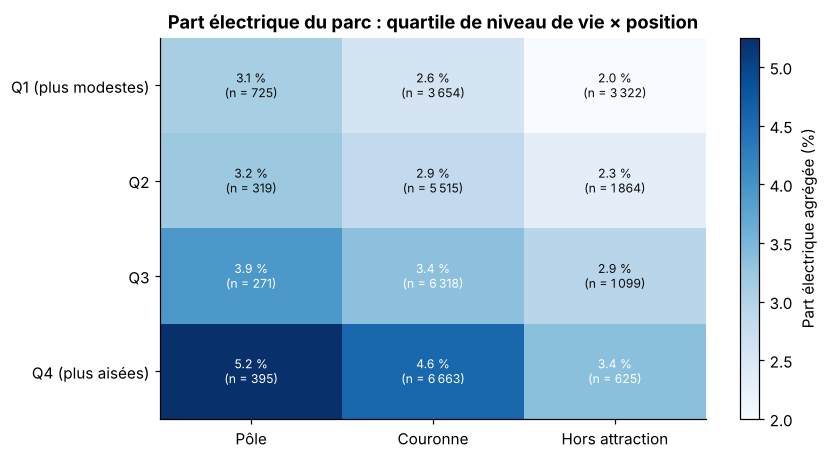

In [28]:
if bornes_revenu is not None:
    parts_croisees, n_croises = ind.tableau_croise(base, "groupe_revenu", "position_aav", "parc")
    graph.tracer_matrice(parts_croisees, n_croises,
                         "Part électrique du parc : quartile de niveau de vie × position", "matrice_revenu_position")

### 7.2 Offre de recharge publique

Deux indicateurs :
- **points de charge pour 1 000 habitants** : l'offre rapportée à la population ;
- **points de charge pour 100 voitures électriques** : l'offre rapportée aux besoins actuels.

Les groupes de densité sont faits sur les points pour 1 000 habitants (ou pour 1 000 voitures si la population manque). Le groupe « Aucun point recensé » n'apparaît que si le rattachement des points IRVE est quasi complet.

In [29]:
colonne_densite = "points_pour_1000_hab" if base["points_pour_1000_hab"].notna().any() else "points_pour_1000_vp"
print("Densité utilisée pour les groupes :", colonne_densite)
base[["points_pour_1000_hab", "points_pour_100_ve", "points_pour_1000_vp"]].describe()

Densité utilisée pour les groupes : points_pour_1000_hab


,points_pour_1000_hab,points_pour_100_ve,points_pour_1000_vp
count,"6,986.00","6,919.00","6,986.00"
mean,6.83,34.66,8.87
std,28.50,160.51,29.54
min,0.03,0.07,0.06
25%,1.04,4.76,1.64
50%,1.99,9.52,3.03
75%,4.29,22.22,6.29
max,"1,200.00","5,800.00",851.45


In [30]:
base = ind.ajouter_classes_recharge(base, colonne_densite)
resume_recharge = ind.resume_par_groupe(base, "classe_recharge", "parc")
resume_recharge

,nb_communes,q1,mediane,q3,vp_elec,vp_total,part_agregee
classe_recharge,,,,,,,
Faible,2329,2.52,3.23,4.18,"545,090.00","14,797,177.00",3.68
Moyenne,2328,2.28,3.11,4.20,"342,020.00","8,754,496.00",3.91
Élevée,2329,1.98,2.99,4.28,"106,753.00","2,656,924.00",4.02


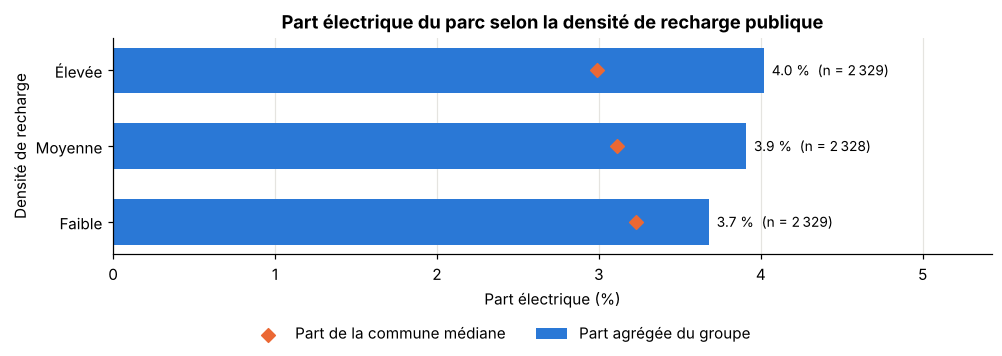

In [31]:
graph.tracer_barres(resume_recharge, "Part électrique du parc selon la densité de recharge publique",
                    "recharge_parc", label_groupe="Densité de recharge", trier=False);

**Commentaire :** *À rédiger. Rappel : la recharge peut suivre l'électrification autant que l'accompagner.*

### 7.3 Accès aux transports collectifs

Présence d'une gare de voyageurs dans la commune (0/1), comparée à type de territoire comparable (position dans l'aire d'attraction).

,nb_communes,q1,mediane,q3,vp_elec,vp_total,part_agregee
gare_libelle,,,,,,,
Sans gare,32201,1.56,2.56,3.74,"775,279.00","22,575,840.00",3.43
Avec gare,2541,2.17,2.90,3.79,"613,745.00","16,425,412.00",3.74


Nombre de communes par case :


gare_libelle,Sans gare,Avec gare
position_aav,,
Pôle,962,751
Couronne,22631,1525
Hors attraction,8608,265


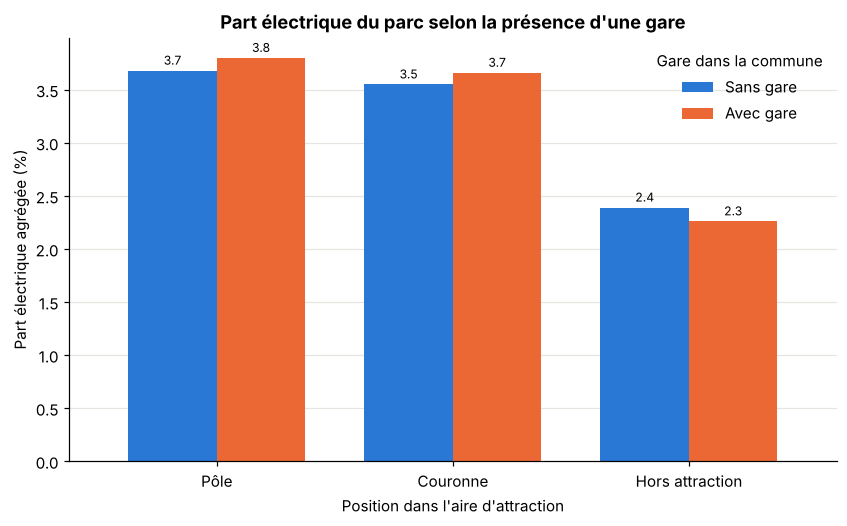

In [32]:
if base["gare"].notna().any():
    base["gare_libelle"] = pd.Categorical(base["gare"].map({1: "Avec gare", 0: "Sans gare"}),
                                          ["Sans gare", "Avec gare"], ordered=True)
    display(ind.resume_par_groupe(base, "gare_libelle", "parc"))
    parts_gare, n_gare = ind.tableau_croise(base, "position_aav", "gare_libelle", "parc")
    graph.tracer_barres_groupees(parts_gare, "Part électrique du parc selon la présence d'une gare",
                                 "barres_gare_position", label_x="Position dans l'aire d'attraction",
                                 label_legende="Gare dans la commune")
    print("Nombre de communes par case :")
    display(n_gare)

In [33]:
# Indicateurs de transport et de recharge par type de territoire, calculés sur le total de chaque groupe
# Attention : les taxis-VTC représentent l'essentiel des "équipements de transport" de la BPE
synthese_position = ind.tableau_synthese(base, "position_aav")
synthese_position

,nb_communes,part VE parc (%),taux VE immat. neuves (%),points de charge,points pour 100 VE,points pour 1 000 hab.,communes avec gare (%),gares pour 100 000 hab.,équip. transport pour 1 000 hab.
position_aav,,,,,,,,,
Pôle,1713,3.76,19.21,"42,481.00",6.75,1.27,43.84,3.06,2.19
Couronne,24158,3.57,22.18,"31,401.00",4.57,1.11,6.31,5.78,0.78
Hors attraction,8875,2.38,20.10,"5,060.00",7.06,1.16,2.99,6.39,0.46
France métropolitaine,34746,3.56,20.37,"78,942.00",5.68,1.19,7.31,4.44,1.47


**Commentaire :** *À rédiger. La présence d'une gare est un repère d'équipement local : elle ne dit rien de la fréquence des trains ni de l'accès aux gares voisines.*

### 7.4 Comparaison des régions

Chaque indicateur est calculé sur le total de la région (somme des numérateurs / somme des dénominateurs), pour comparer des régions de tailles différentes.

In [34]:
regions = ind.tableau_synthese(base, "region")
regions.to_csv(config.DOSSIER_PREP / "tableau_regions.csv")
regions

,nb_communes,part VE parc (%),taux VE immat. neuves (%),points de charge,points pour 100 VE,points pour 1 000 hab.,communes avec gare (%),gares pour 100 000 hab.,équip. transport pour 1 000 hab.
region,,,,,,,,,
Auvergne-Rhône-Alpes,4025,3.62,21.74,"8,707.00",4.73,1.06,7.08,4.00,0.90
Bourgogne-Franche-Comté,3685,2.56,18.97,"2,789.00",5.99,1.00,5.05,6.99,0.50
Bretagne,1202,3.04,20.10,"3,726.00",5.53,1.08,8.99,3.54,0.43
Centre-Val de Loire,1754,2.85,19.80,"2,302.00",4.93,0.89,8.55,6.15,0.70
Corse,360,4.99,19.22,294.00,2.63,0.83,8.89,17.44,1.08
Grand Est,5115,3.31,20.93,"5,829.00",5.10,1.05,6.08,6.09,0.57
Hauts-de-France,3782,3.29,17.07,"8,430.00",7.23,1.41,8.09,5.47,0.76
Normandie,2644,3.29,18.40,"5,859.00",8.48,1.75,3.48,2.81,0.50
Nouvelle-Aquitaine,4293,3.01,19.05,"6,806.00",5.60,1.11,6.83,4.98,0.69


**Commentaire :** *À rédiger.*

## 8. Vérifications de sensibilité et extension

### 8.1 Petits effectifs (immatriculations neuves)

In [35]:
ind.sensibilite_petits_effectifs(base, "position_aav", "neuf")

Communes retirées (moins de 20 immatriculations) : 26,269
Immatriculations retirées : 139,576 sur 1,605,451


toutes les communes                      au moins 20 immat.  \
                        nb_communes mediane part_agregee        nb_communes   
position_aav                                                                  
Pôle                           1710   18.47        19.21               1595   
Couronne                      22481   21.05        22.18               6080   
Hors attraction                7305   14.29        20.10                775   

                                      
                mediane part_agregee  
position_aav                          
Pôle              18.45        19.21  
Couronne          22.73        21.82  
Hors attraction   19.05        19.32

### 8.2 Statut d'utilisateur : ménages

In [36]:
pd.concat({
    "tous utilisateurs": ind.resume_par_groupe(base, "position_aav", "neuf")[["nb_communes", "part_agregee"]],
    "ménages": ind.resume_par_groupe(base, "position_aav", "neuf", menages=True)[["nb_communes", "part_agregee"]],
}, axis=1)

tous utilisateurs                  ménages             
                      nb_communes part_agregee nb_communes part_agregee
position_aav                                                           
Pôle                         1710        19.21        1710        18.42
Couronne                    22481        22.18       22315        23.99
Hors attraction              7305        20.10        7177        21.13

### 8.3 Extension : neuf et occasion en 2025 (chaque marché avec son propre total)

In [37]:
pd.DataFrame({
    "part neuf (%)": ind.resume_par_groupe(base, "position_aav", "neuf")["part_agregee"],
    "part occasion (%)": ind.resume_par_groupe(base, "position_aav", "occasion")["part_agregee"],
})

,part neuf (%),part occasion (%)
position_aav,,
Pôle,19.21,3.09
Couronne,22.18,3.64
Hors attraction,20.10,2.45


## 9. Conclusion et limites

*À rédiger à partir des résultats calculés : deux ou trois résultats chiffrés avec leur périmètre, puis les limites.*

Limites à discuter :
- les associations sont mesurées à l'échelle des communes : elles ne disent pas quels ménages achètent une voiture électrique ;
- la localisation des voitures de société et de location dépend de l'adresse du titulaire (sièges sociaux) ;
- l'IRVE est daté d'octobre 2026, le parc de janvier 2026 ;
- les petits effectifs rendent les parts communales du neuf instables.